In [1]:

import math
import numpy as np
import matplotlib.pyplot as plt

SEED = 12345
N_PER_CLASS = 500          # points generated per class

K = {0: 2, 1: 2}

PI = {0: [0.6, 0.4],
      1: [0.5, 0.5]}

# mu_i : mean 
MU = {0: [np.array([0.0, 0.0]), np.array([4.0, 4.0])],
      1: [np.array([4.0, 0.0]), np.array([0.0, 4.0])]}

# Covariance cases. For each component we store a matrix A, and C = A A^T.
# Generation later uses x = mu + A z, which gives Cov(x) = A A^T = C.
def sph(s):      return np.array([[s, 0.0], [0.0, s]])      # C = s^2 I
def diag(sx, sy): return np.array([[sx, 0.0], [0.0, sy]])   # C = diag(sx^2, sy^2)

A = {
    "spherical": {0: [sph(1.0), sph(1.2)],
                  1: [sph(1.0), sph(1.2)]},
    "diagonal":  {0: [diag(1.5, 0.6), diag(0.6, 1.5)],
                  1: [diag(1.5, 0.6), diag(0.6, 1.5)]},
    "full":      {0: [np.array([[1.2, 0.0], [0.9, 0.6]]),
                      np.array([[1.0, 0.0], [-0.8, 0.7]])],
                  1: [np.array([[1.2, 0.0], [-0.9, 0.6]]),
                      np.array([[1.0, 0.0], [0.8, 0.7]])]},
}

# C_i = A_i A_i^T for every case / class / component
C = {case: {c: [Ai @ Ai.T for Ai in A[case][c]] for c in (0, 1)} for case in A}

# basic checks: weights sum to 1, list lengths match K
for c in (0, 1):
    assert abs(sum(PI[c]) - 1.0) < 1e-9
    assert len(PI[c]) == len(MU[c]) == K[c]
    for case in A:
        assert len(A[case][c]) == K[c]

for case in C:
    print(case, "class 0 C_1 =\n", C[case][0][0])

spherical class 0 C_1 =
 [[1. 0.]
 [0. 1.]]
diagonal class 0 C_1 =
 [[2.25 0.  ]
 [0.   0.36]]
full class 0 C_1 =
 [[1.44 1.08]
 [1.08 1.17]]


In [2]:
# Box-Muller needs uniform numbers in (0,1). np.random / random are blocked,
# so we generate them ourselves with a Linear Congruential Generator.

class LCG:
    def __init__(self, seed):
        self.state = seed % 2**32

    def uniform(self):
        self.state = (1664525 * self.state + 1013904223) % 2**32
        return (self.state + 0.5) / 2**32     # strictly between 0 and 1

rng = LCG(SEED)
print([round(rng.uniform(), 4) for _ in range(5)])

[0.0204, 0.0165, 0.5432, 0.6349, 0.91]


In [3]:
# Run in the same notebook after cells 1-2 (Shift+Enter).
# Box-Muller: two uniforms -> one 2D standard normal vector z (each component N(0,1)).

def box_muller(rng):
    u1 = rng.uniform()
    u2 = rng.uniform()
    r = math.sqrt(-2.0 * math.log(u1))
    return np.array([r * math.cos(2 * math.pi * u2),
                     r * math.sin(2 * math.pi * u2)])

print(box_muller(LCG(SEED)))

[2.77494684 0.28956429]


In [4]:
# Run after cell 3.
# For each point: 1 uniform picks the component using pi, 2 uniforms feed Box-Muller,
# then x = mu_i + A_i z, which has covariance C_i = A_i A_i^T.

def pick_component(u, pis):
    cum = 0.0
    for i, p in enumerate(pis):
        cum += p
        if u < cum:
            return i
    return len(pis) - 1

def generate_class(c, case, rng):
    X = np.zeros((N_PER_CLASS, 2))
    comp = np.zeros(N_PER_CLASS, dtype=int)
    for n in range(N_PER_CLASS):
        i = pick_component(rng.uniform(), PI[c])
        z = box_muller(rng)
        X[n] = MU[c][i] + A[case][c][i] @ z
        comp[n] = i
    return X, comp

DATA = {}                      # DATA[case][class] = (points, component labels)
for case in A:
    rng = LCG(SEED)            # same seed per case, so only the covariance changes
    DATA[case] = {c: generate_class(c, case, rng) for c in (0, 1)}

for case in DATA:
    print(case, DATA[case][0][0].shape, DATA[case][1][0].shape)

spherical (500, 2) (500, 2)
diagonal (500, 2) (500, 2)
full (500, 2) (500, 2)


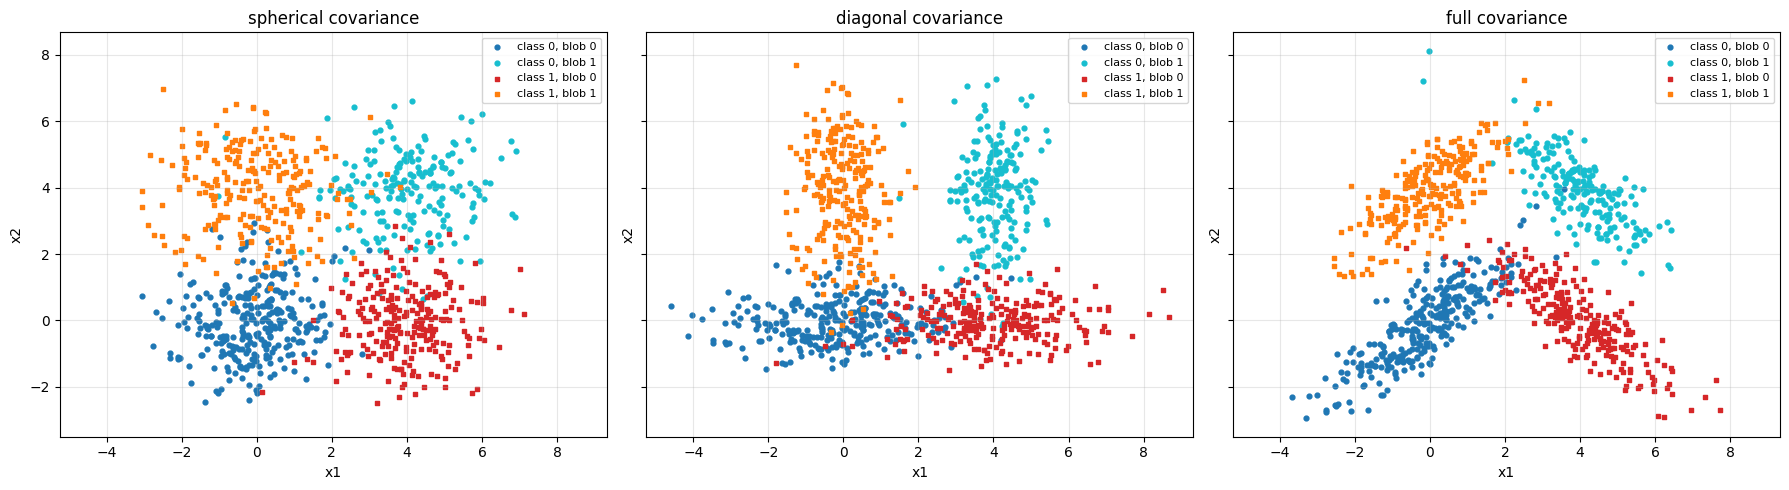

In [5]:
# Run after cell 4. One subplot per covariance case.
# Colour = component (blob), marker = class.

colors  = {0: ["tab:blue", "tab:cyan"],      # class 0: component 0, component 1
           1: ["tab:red",  "tab:orange"]}    # class 1: component 0, component 1
markers = {0: "o", 1: "s"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, case in zip(axes, DATA):
    for c in (0, 1):
        X, comp = DATA[case][c]
        for i in range(K[c]):
            pts = X[comp == i]
            ax.scatter(pts[:, 0], pts[:, 1], s=12, c=colors[c][i], marker=markers[c],
                       label=f"class {c}, blob {i}")
    ax.set_title(f"{case} covariance")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Run after cell 4 (cell 5 is only the plot, so it can be skipped).
# The data was generated in random order (blob chosen at random per point),
# so the first 80% / last 20% is already a random split. No shuffle needed.

SPLIT = 0.8
n_train = int(SPLIT * N_PER_CLASS)

TRAIN, TEST = {}, {}      # TRAIN[case][class] = points, TEST[case][class] = points
for case in DATA:
    TRAIN[case] = {c: DATA[case][c][0][:n_train] for c in (0, 1)}
    TEST[case]  = {c: DATA[case][c][0][n_train:] for c in (0, 1)}
    print(case, "train:", TRAIN[case][0].shape, TRAIN[case][1].shape,
                "test:",  TEST[case][0].shape,  TEST[case][1].shape)

spherical train: (400, 2) (400, 2) test: (100, 2) (100, 2)
diagonal train: (400, 2) (400, 2) test: (100, 2) (100, 2)
full train: (400, 2) (400, 2) test: (100, 2) (100, 2)


In [7]:
# Run after cell 6 (Shift+Enter, top to bottom).
# K-means: repeat (assign each point to nearest centroid) -> (move centroid to mean of its points)
# until the centroids stop changing. Distance used = squared Euclidean.

def kmeans(X, K, max_iter=100):
    centroids = X[:K].copy()       # init: first K training points (data order is already random)
    for _ in range(max_iter):
        # squared distance from every point to every centroid -> shape (n, K)
        d = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        labels = d.argmin(axis=1)

        new_centroids = centroids.copy()
        for k in range(K):
            if np.any(labels == k):                    # skip empty clusters
                new_centroids[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_centroids, centroids):      # converged
            break
        centroids = new_centroids
    return centroids, labels

In [8]:
# Run after cell 7. K-means is run separately for each class and each covariance case.

CENTROIDS = {}     # CENTROIDS[case][class] = (K, 2) array
LABELS = {}        # LABELS[case][class] = cluster index of each training point

for case in TRAIN:
    CENTROIDS[case], LABELS[case] = {}, {}
    for c in (0, 1):
        CENTROIDS[case][c], LABELS[case][c] = kmeans(TRAIN[case][c], K[c])

    print(case)
    for c in (0, 1):
        print("  class", c, "centroids:\n", np.round(CENTROIDS[case][c], 2))
        print("  class", c, "designed means:\n", np.array(MU[c]))

spherical
  class 0 centroids:
 [[-0.15 -0.04]
 [ 4.03  3.86]]
  class 0 designed means:
 [[0. 0.]
 [4. 4.]]
  class 1 centroids:
 [[ 3.96 -0.02]
 [-0.12  3.92]]
  class 1 designed means:
 [[4. 0.]
 [0. 4.]]
diagonal
  class 0 centroids:
 [[-0.28 -0.05]
 [ 3.99  3.75]]
  class 0 designed means:
 [[0. 0.]
 [4. 4.]]
  class 1 centroids:
 [[ 3.96 -0.01]
 [-0.06  3.89]]
  class 1 designed means:
 [[4. 0.]
 [0. 4.]]
full
  class 0 centroids:
 [[-0.25 -0.23]
 [ 3.95  3.88]]
  class 0 designed means:
 [[0. 0.]
 [4. 4.]]
  class 1 centroids:
 [[ 4.07 -0.07]
 [-0.04  3.81]]
  class 1 designed means:
 [[4. 0.]
 [0. 4.]]


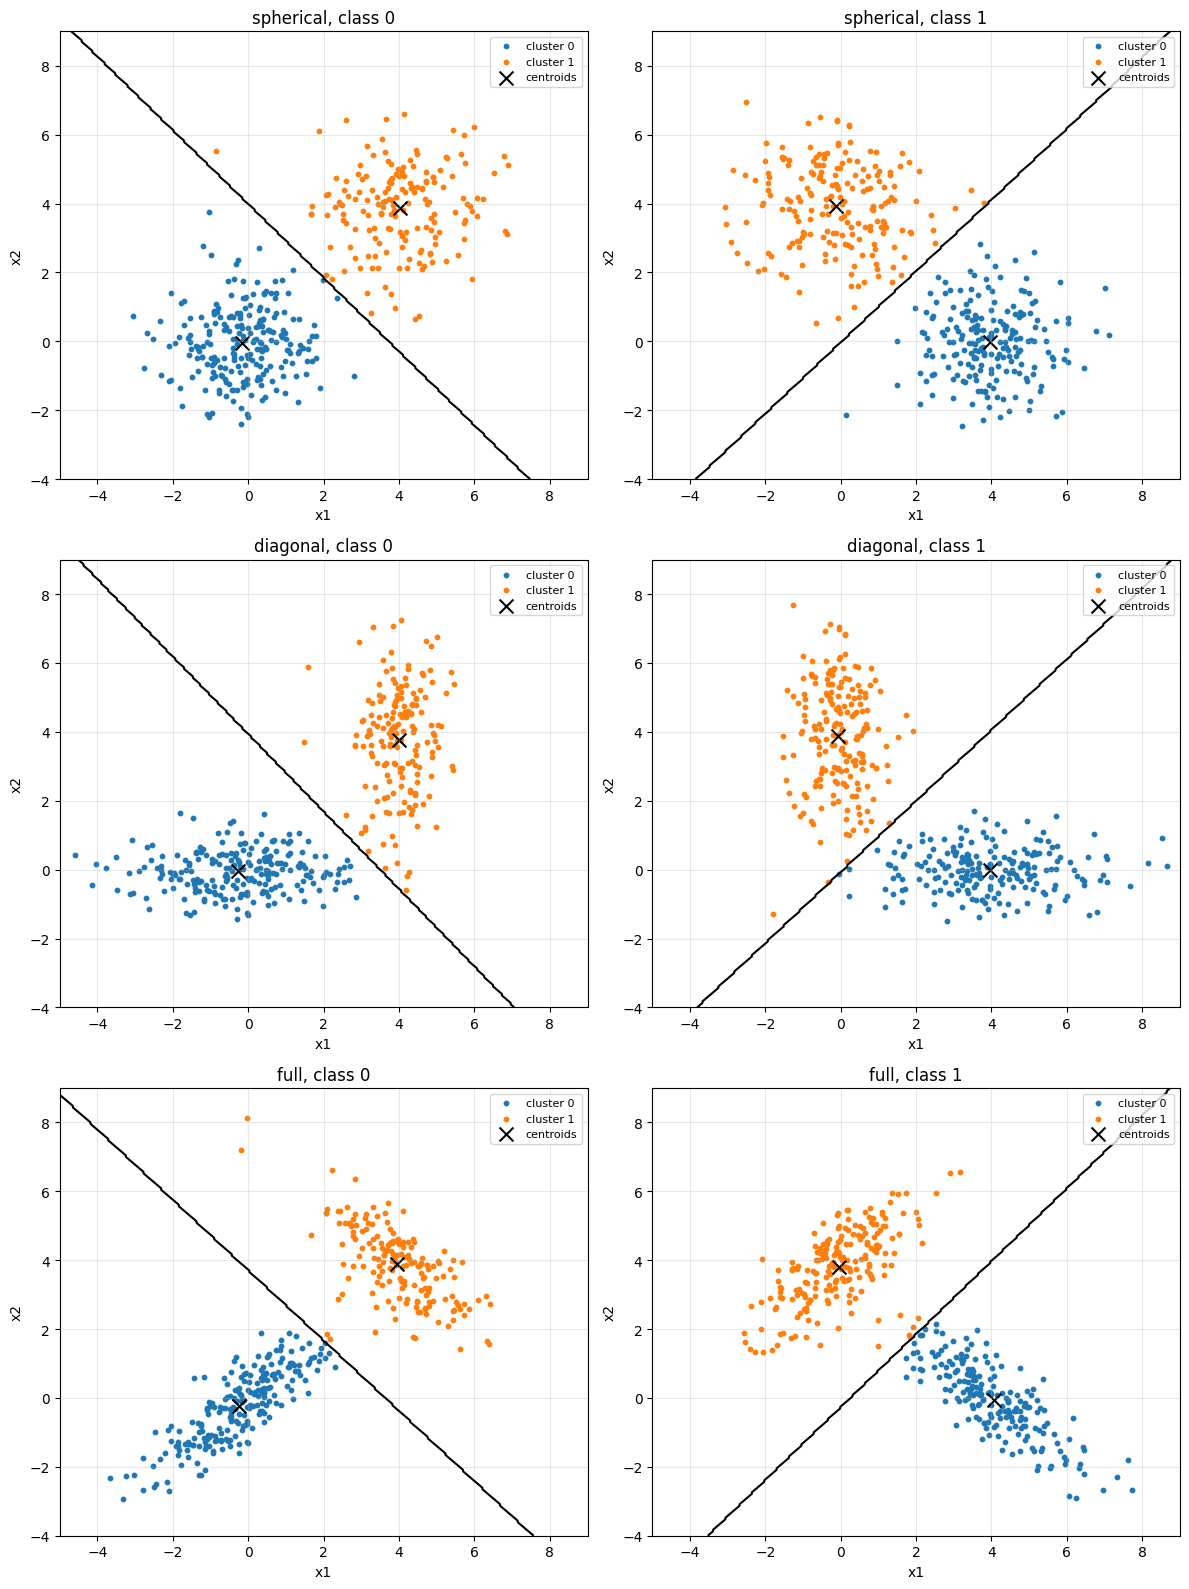

In [9]:
# Run after cell 8. Rows = covariance case, columns = class.
# Boundary between clusters = the set of points equally close to two centroids.
# We evaluate "nearest centroid" on a grid and draw where the label changes.

cluster_colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple"]

fig, axes = plt.subplots(3, 2, figsize=(12, 16))
for row, case in enumerate(TRAIN):
    for c in (0, 1):
        ax = axes[row, c]
        X = TRAIN[case][c]
        cent = CENTROIDS[case][c]

        # grid over the plotting area
        xs = np.linspace(-5, 9, 300)
        ys = np.linspace(-4, 9, 300)
        xx, yy = np.meshgrid(xs, ys)
        pts = np.stack([xx.ravel(), yy.ravel()], axis=1)
        d = ((pts[:, None, :] - cent[None, :, :]) ** 2).sum(axis=2)
        grid_labels = d.argmin(axis=1).reshape(xx.shape)

        # points coloured by cluster
        for k in range(K[c]):
            ax.scatter(X[LABELS[case][c] == k, 0], X[LABELS[case][c] == k, 1],
                       s=10, c=cluster_colors[k], label=f"cluster {k}")
        ax.scatter(cent[:, 0], cent[:, 1], c="k", marker="x", s=100, label="centroids")
        ax.contour(xx, yy, grid_labels, levels=np.arange(K[c] - 1) + 0.5, colors="k")

        ax.set_title(f"{case}, class {c}")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:

# Distortion of a point x under class c:  D_c(x) = min over k of ||x - mu_ck||^2
# Predicted class = the class with the smaller distortion.

PRED = {}      # PRED[case][true class] = predicted class for each test point of that class

for case in TEST:
    PRED[case] = {}
    for c in (0, 1):
        X = TEST[case][c]
        D = []
        for cls in (0, 1):
            cent = CENTROIDS[case][cls]
            d = ((X[:, None, :] - cent[None, :, :]) ** 2).sum(axis=2)
            D.append(d.min(axis=1))          # distortion of each point under class cls
        D = np.stack(D, axis=1)              # shape (n_test, 2)
        PRED[case][c] = D.argmin(axis=1)

In [12]:
for case in PRED:
    correct0 = np.sum(PRED[case][0] == 0)
    correct1 = np.sum(PRED[case][1] == 1)
    total = len(PRED[case][0]) + len(PRED[case][1])
    print(f"{case}: class 0 {correct0}/{len(PRED[case][0])}, "
          f"class 1 {correct1}/{len(PRED[case][1])}, "
          f"overall {(correct0 + correct1) / total:.3f}")

spherical: class 0 92/100, class 1 88/100, overall 0.900
diagonal: class 0 92/100, class 1 89/100, overall 0.905
full: class 0 94/100, class 1 95/100, overall 0.945
